In [1]:
# Loading the cleaned retail sales dataset from the processed data folder for sales forecasting

import pandas as pd

df = pd.read_csv("../data/processed/cleaned_data.csv")

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (100000, 28)


,Customer ID,Customer Name,Last Name,Date of Birth,Sales,Year,Outlet Type,City Type,Category of Goods,Region,...,Postal Code,Product ID,Sub-Category,Product Name,Quantity,Discount,Profit,Month,Quarter,Year-Month
0,CUST000001,Curtis,Krause,1973-11-29,3344.69,2020,Large,Tier 1,Fast Food,East,...,700001,PROD000001,Burgers,Burgers - 718,3,0.09,448.24,4,2,2020-04
1,CUST000002,Jeremy,Foster,1987-08-30,37094.41,2021,Medium,Tier 2,Fast Food,East,...,160001,PROD000002,Pizzas,Pizzas - 519,5,0.39,3134.34,1,1,2021-01
2,CUST000003,Ariel,Mccann,1980-12-15,35501.08,2020,Large,Village,Electric Appliances,South,...,380001,PROD000003,Fans,Fans - 395,6,0.07,8324.21,8,3,2020-08
3,CUST000004,Colleen,Maynard,1989-05-23,8969.33,2021,Medium,Village,Dairy Products,East,...,700001,PROD000004,Milk,Milk - 798,4,0.18,1962.66,10,4,2021-10
4,CUST000005,Gina,Holden,1957-12-31,35530.44,2019,Small,Village,Sessional Fruits & Vegetables,West,...,110001,PROD000005,Tomatoes,Tomatoes - 442,4,0.27,2843.93,1,1,2019-01


In [2]:
# Checking and converting the Order Date column into datetime format before creating the monthly sales time series

df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")

print("Order Date Data Type:", df["Order Date"].dtype)
print("Invalid Order Dates:", df["Order Date"].isna().sum())
print("Order Date Range:")
print("Start:", df["Order Date"].min())
print("End:", df["Order Date"].max())

Order Date Data Type: datetime64[us]
Invalid Order Dates: 0
Order Date Range:
Start: 2019-01-01 00:00:00
End: 2023-12-31 00:00:00


In [3]:
# Aggregating transaction-level sales into monthly total sales to create the time series required for forecasting

monthly_sales = (
    df.groupby(df["Order Date"].dt.to_period("M"))["Sales"]
    .sum()
    .reset_index()
)

monthly_sales.columns = ["Year-Month", "Total_Sales"]

monthly_sales["Year-Month"] = monthly_sales["Year-Month"].dt.to_timestamp()

display(monthly_sales.head())
print("\nNumber of monthly observations:", len(monthly_sales))
print("Start Month:", monthly_sales["Year-Month"].min())
print("End Month:", monthly_sales["Year-Month"].max())

,Year-Month,Total_Sales
0,2019-01-01,42344783.81
1,2019-02-01,37865145.00
2,2019-03-01,43913954.31
3,2019-04-01,40725028.79
4,2019-05-01,42081183.23



Number of monthly observations: 60
Start Month: 2019-01-01 00:00:00
End Month: 2023-12-01 00:00:00


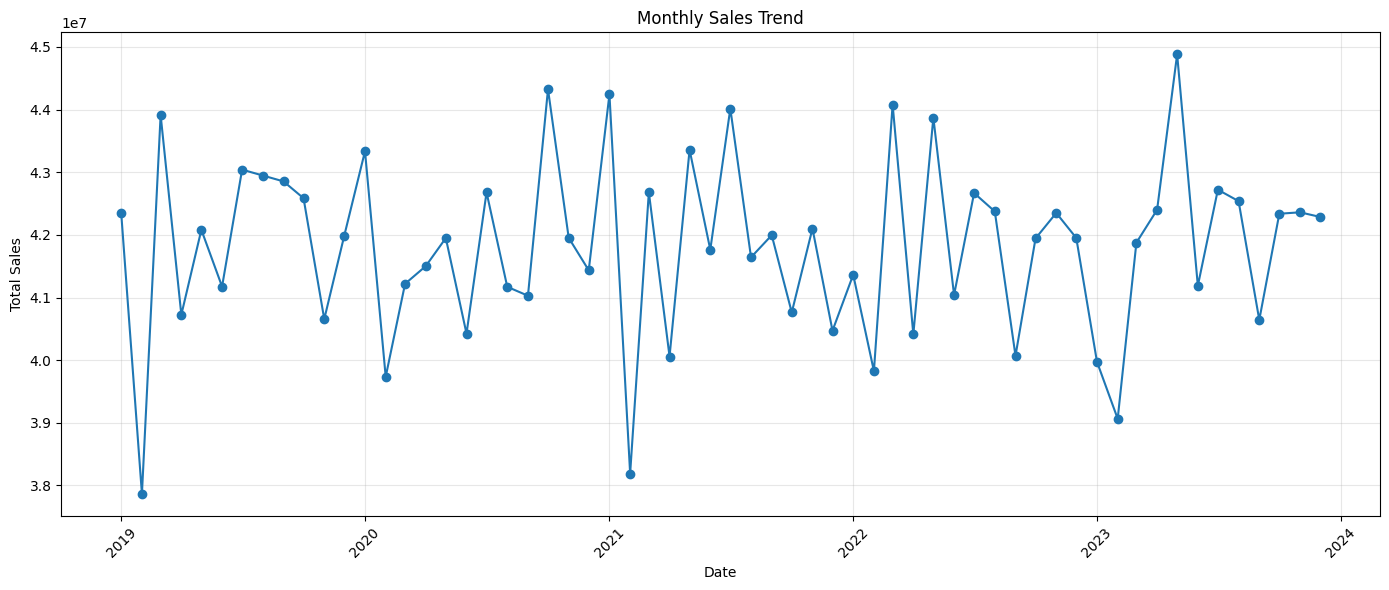

In [4]:
# Visualizing the monthly sales time series to identify overall trends and recurring patterns before selecting forecasting models

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales["Year-Month"],
    monthly_sales["Total_Sales"],
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.grid(True, alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [5]:
# Comparing monthly sales across different years to identify recurring seasonal patterns and year-to-year changes

monthly_comparison = monthly_sales.copy()

monthly_comparison["Year"] = monthly_comparison["Year-Month"].dt.year
monthly_comparison["Month"] = monthly_comparison["Year-Month"].dt.month

monthly_comparison_pivot = monthly_comparison.pivot(
    index="Month",
    columns="Year",
    values="Total_Sales"
)

display(monthly_comparison_pivot)

Year,2019,2020,2021,2022,2023
Month,,,,,
1,42344783.81,43335493.32,44244055.65,41364166.54,39973456.60
2,37865145.00,39734929.06,38189285.71,39825720.26,39064577.96
3,43913954.31,41219136.88,42681623.08,44081165.74,41875082.29
4,40725028.79,41501540.88,40058619.74,40412336.68,42400498.84
5,42081183.23,41949577.55,43358314.33,43873430.73,44882357.95
6,41175051.76,40424208.29,41763394.14,41039709.21,41187338.18
7,43041403.30,42678848.46,44016335.94,42668071.62,42721138.18
8,42947691.21,41171210.53,41642164.79,42374034.11,42538982.80
9,42853719.63,41028621.71,41995031.18,40070326.06,40642795.64


In [6]:
# Calculating average sales for each calendar month across all five years to measure recurring seasonal patterns

seasonal_sales = (
    monthly_comparison.groupby("Month")["Total_Sales"]
    .mean()
    .reset_index()
)

seasonal_sales["Month_Name"] = pd.to_datetime(
    seasonal_sales["Month"], format="%m"
).dt.strftime("%B")

display(seasonal_sales)

,Month,Total_Sales,Month_Name
0,1,4.225239e+07,January
1,2,3.893593e+07,February
2,3,4.275419e+07,March
3,4,4.101960e+07,April
4,5,4.322897e+07,May
5,6,4.111794e+07,June
6,7,4.302516e+07,July
7,8,4.213482e+07,August
8,9,4.131810e+07,September
9,10,4.239066e+07,October


In [7]:
# Calculating a three-month rolling average to smooth short-term fluctuations and reveal the underlying sales trend

monthly_sales["Rolling_3M_Sales"] = (
    monthly_sales["Total_Sales"]
    .rolling(window=3)
    .mean()
)

display(monthly_sales.head(10))

,Year-Month,Total_Sales,Rolling_3M_Sales
0,2019-01-01,42344783.81,NaN
1,2019-02-01,37865145.00,NaN
2,2019-03-01,43913954.31,4.137463e+07
3,2019-04-01,40725028.79,4.083471e+07
4,2019-05-01,42081183.23,4.224006e+07
5,2019-06-01,41175051.76,4.132709e+07
6,2019-07-01,43041403.30,4.209921e+07
7,2019-08-01,42947691.21,4.238805e+07
8,2019-09-01,42853719.63,4.294760e+07
9,2019-10-01,42585146.28,4.279552e+07


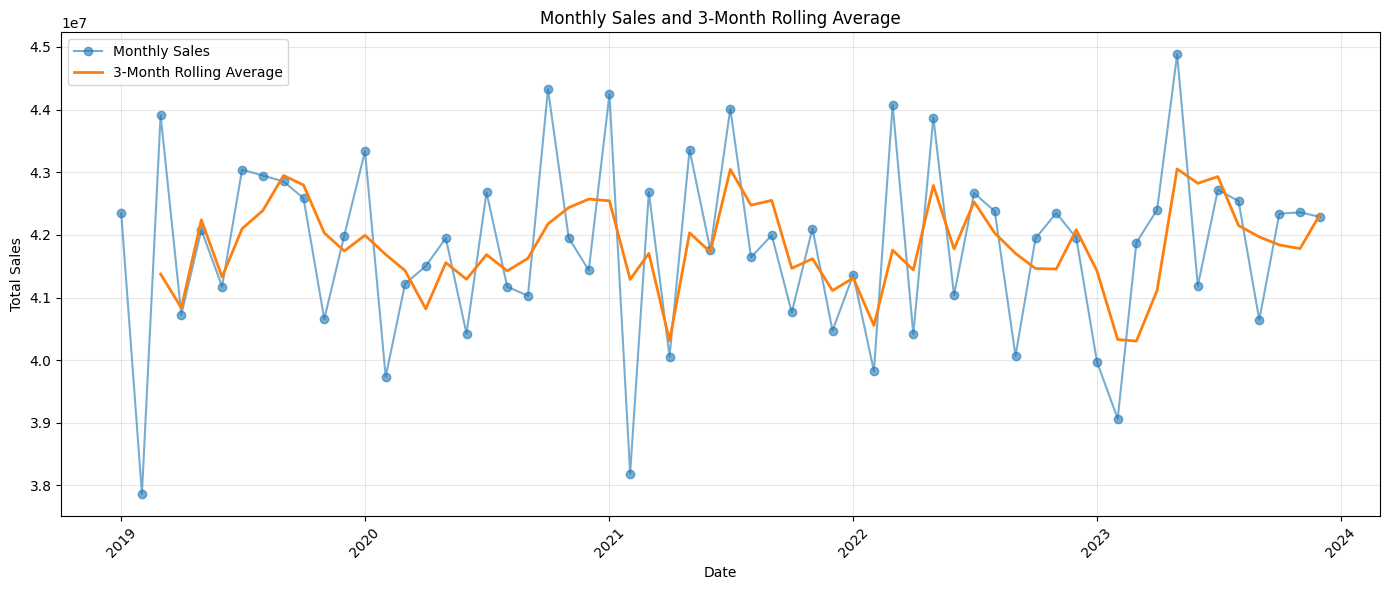

In [8]:
# Visualizing monthly sales together with the three-month rolling average to identify the underlying sales trend

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales["Year-Month"],
    monthly_sales["Total_Sales"],
    label="Monthly Sales",
    marker="o",
    alpha=0.6
)

plt.plot(
    monthly_sales["Year-Month"],
    monthly_sales["Rolling_3M_Sales"],
    label="3-Month Rolling Average",
    linewidth=2
)

plt.title("Monthly Sales and 3-Month Rolling Average")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.legend()
plt.grid(True, alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [9]:
'''
Since we have 60 monthly observations, we'll use:

First 48 months (2019–2022) → Training data
Last 12 months (2023) → Testing data
'''

"\nSince we have 60 monthly observations, we'll use:\n\nFirst 48 months (2019–2022) → Training data\nLast 12 months (2023) → Testing data\n"

In [10]:
# Splitting the monthly sales time series chronologically into training data and the final twelve months for testing

train = monthly_sales.iloc[:-12].copy()
test = monthly_sales.iloc[-12:].copy()

print("Training Data:")
print("Start:", train["Year-Month"].min())
print("End:", train["Year-Month"].max())
print("Observations:", len(train))

print("\nTesting Data:")
print("Start:", test["Year-Month"].min())
print("End:", test["Year-Month"].max())
print("Observations:", len(test))

Training Data:
Start: 2019-01-01 00:00:00
End: 2022-12-01 00:00:00
Observations: 48

Testing Data:
Start: 2023-01-01 00:00:00
End: 2023-12-01 00:00:00
Observations: 12


In [11]:
# Creating a seasonal naive baseline by using the corresponding month from the previous year as the forecast

test["Baseline_Forecast"] = train["Total_Sales"].iloc[-12:].values

display(
    test[
        ["Year-Month", "Total_Sales", "Baseline_Forecast"]
    ]
)

,Year-Month,Total_Sales,Baseline_Forecast
48,2023-01-01,39973456.60,41364166.54
49,2023-02-01,39064577.96,39825720.26
50,2023-03-01,41875082.29,44081165.74
51,2023-04-01,42400498.84,40412336.68
52,2023-05-01,44882357.95,43873430.73
53,2023-06-01,41187338.18,41039709.21
54,2023-07-01,42721138.18,42668071.62
55,2023-08-01,42538982.80,42374034.11
56,2023-09-01,40642795.64,40070326.06
57,2023-10-01,42337414.55,41943375.86


In [12]:
# Calculating MAE, RMSE, and MAPE for the seasonal naive baseline to establish a reference forecasting performance

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

actual = test["Total_Sales"]
baseline = test["Baseline_Forecast"]

baseline_mae = mean_absolute_error(actual, baseline)
baseline_rmse = np.sqrt(mean_squared_error(actual, baseline))
baseline_mape = np.mean(
    np.abs((actual - baseline) / actual)
) * 100

print("Seasonal Naive Baseline Performance")
print("-----------------------------------")
print(f"MAE  : ₹{baseline_mae:,.2f}")
print(f"RMSE : ₹{baseline_rmse:,.2f}")
print(f"MAPE : {baseline_mape:.2f}%")

Seasonal Naive Baseline Performance
-----------------------------------
MAE  : ₹752,789.56
RMSE : ₹1,040,780.10
MAPE : 1.81%


In [13]:
# Preparing the training sales series as a monthly time-indexed series for fitting the ARIMA forecasting model

train_series = train.set_index("Year-Month")["Total_Sales"]

train_series = train_series.asfreq("MS")

print("Training Series Length:", len(train_series))
print("Frequency:", train_series.index.freq)
print("Missing Values:", train_series.isna().sum())
display(train_series.head())

Training Series Length: 48
Frequency: <MonthBegin>
Missing Values: 0


Year-Month
2019-01-01    42344783.81
2019-02-01    37865145.00
2019-03-01    43913954.31
2019-04-01    40725028.79
2019-05-01    42081183.23
Freq: MS, Name: Total_Sales, dtype: float64

In [14]:
# Fitting an ARIMA model on the training sales series to generate forecasts for the twelve-month test period

from statsmodels.tsa.arima.model import ARIMA

arima_model = ARIMA(
    train_series,
    order=(1, 1, 1)
)

arima_result = arima_model.fit()

print(arima_result.summary())

                               SARIMAX Results                                
Dep. Variable:            Total_Sales   No. Observations:                   48
Model:                 ARIMA(1, 1, 1)   Log Likelihood                -753.504
Date:                Wed, 23 Sep 2026   AIC                           1513.009
Time:                        16:00:21   BIC                           1518.559
Sample:                    01-01-2019   HQIC                          1515.097
                         - 12-01-2022                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.6935      0.100     -6.957      0.000      -0.889      -0.498
ma.L1          0.5433      0.110      4.923      0.000       0.327       0.760
sigma2      1.889e+12   2.46e-14   7.67e+25      0.0

In [15]:
# Generating twelve monthly sales forecasts from the fitted ARIMA model for the 2023 test period

arima_forecast = arima_result.forecast(steps=len(test))

test["ARIMA_Forecast"] = arima_forecast.values

display(
    test[
        ["Year-Month", "Total_Sales", "Baseline_Forecast", "ARIMA_Forecast"]
    ]
)

,Year-Month,Total_Sales,Baseline_Forecast,ARIMA_Forecast
48,2023-01-01,39973456.60,41364166.54,4.194679e+07
49,2023-02-01,39064577.96,39825720.26,4.194950e+07
50,2023-03-01,41875082.29,44081165.74,4.194762e+07
51,2023-04-01,42400498.84,40412336.68,4.194892e+07
52,2023-05-01,44882357.95,43873430.73,4.194802e+07
53,2023-06-01,41187338.18,41039709.21,4.194865e+07
54,2023-07-01,42721138.18,42668071.62,4.194821e+07
55,2023-08-01,42538982.80,42374034.11,4.194851e+07
56,2023-09-01,40642795.64,40070326.06,4.194830e+07
57,2023-10-01,42337414.55,41943375.86,4.194845e+07


In [17]:
'''
The ARIMA forecast is behaving as expected from this configuration: after the first forecast, 
it converges toward roughly ₹41.95M per month, so it is not capturing the month-to-month seasonal variation that our baseline does.
'''

'\nThe ARIMA forecast is behaving as expected from this configuration: after the first forecast, \nit converges toward roughly ₹41.95M per month, so it is not capturing the month-to-month seasonal variation that our baseline does.\n'

In [18]:
# Calculating MAE, RMSE, and MAPE for the ARIMA forecasts using the same 2023 test data as the baseline

arima_mae = mean_absolute_error(
    test["Total_Sales"],
    test["ARIMA_Forecast"]
)

arima_rmse = np.sqrt(
    mean_squared_error(
        test["Total_Sales"],
        test["ARIMA_Forecast"]
    )
)

arima_mape = np.mean(
    np.abs(
        (test["Total_Sales"] - test["ARIMA_Forecast"])
        / test["Total_Sales"]
    )
) * 100

print("ARIMA(1,1,1) Performance")
print("------------------------")
print(f"MAE  : ₹{arima_mae:,.2f}")
print(f"RMSE : ₹{arima_rmse:,.2f}")
print(f"MAPE : {arima_mape:.2f}%")

ARIMA(1,1,1) Performance
------------------------
MAE  : ₹1,073,846.95
RMSE : ₹1,434,742.48
MAPE : 2.59%


In [20]:
# Fitting a seasonal ARIMA model with a twelve-month seasonal cycle to capture both trend and recurring monthly patterns

from statsmodels.tsa.statespace.sarimax import SARIMAX

sarima_model = SARIMAX(
    train_series,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarima_result = sarima_model.fit(disp=False)

print(sarima_result.summary())

C:\Users\SRIDHAR\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\sarimax.py:866: UserWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  warn('Too few observations to estimate starting parameters%s.'


                                     SARIMAX Results                                      
Dep. Variable:                        Total_Sales   No. Observations:                   48
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood                -328.634
Date:                            Wed, 23 Sep 2026   AIC                            667.268
Time:                                    16:03:52   BIC                            672.491
Sample:                                01-01-2019   HQIC                           668.402
                                     - 12-01-2022                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.3326      0.309     -1.077      0.281      -0.938       0.273
ma.L1         -0.3303      0.185   

In [21]:
# Generating twelve monthly sales forecasts from the fitted SARIMA model for the 2023 test period

sarima_forecast = sarima_result.forecast(
    steps=len(test)
)

test["SARIMA_Forecast"] = sarima_forecast.values

display(
    test[
        [
            "Year-Month",
            "Total_Sales",
            "Baseline_Forecast",
            "ARIMA_Forecast",
            "SARIMA_Forecast"
        ]
    ]
)

,Year-Month,Total_Sales,Baseline_Forecast,ARIMA_Forecast,SARIMA_Forecast
48,2023-01-01,39973456.60,41364166.54,4.194679e+07,4.309197e+07
49,2023-02-01,39064577.96,39825720.26,4.194950e+07,3.968067e+07
50,2023-03-01,41875082.29,44081165.74,4.194762e+07,4.392246e+07
51,2023-04-01,42400498.84,40412336.68,4.194892e+07,4.082448e+07
52,2023-05-01,44882357.95,43873430.73,4.194802e+07,4.414795e+07
53,2023-06-01,41187338.18,41039709.21,4.194865e+07,4.190435e+07
54,2023-07-01,42721138.18,42668071.62,4.194821e+07,4.382679e+07
55,2023-08-01,42538982.80,42374034.11,4.194851e+07,4.256712e+07
56,2023-09-01,40642795.64,40070326.06,4.194830e+07,4.150990e+07
57,2023-10-01,42337414.55,41943375.86,4.194845e+07,4.199757e+07


In [22]:
# Calculating MAE, RMSE, and MAPE for the SARIMA forecasts using the same 2023 test data as the other models

sarima_mae = mean_absolute_error(
    test["Total_Sales"],
    test["SARIMA_Forecast"]
)

sarima_rmse = np.sqrt(
    mean_squared_error(
        test["Total_Sales"],
        test["SARIMA_Forecast"]
    )
)

sarima_mape = np.mean(
    np.abs(
        (test["Total_Sales"] - test["SARIMA_Forecast"])
        / test["Total_Sales"]
    )
) * 100

print("SARIMA(1,1,1)x(1,1,1,12) Performance")
print("-------------------------------------")
print(f"MAE  : ₹{sarima_mae:,.2f}")
print(f"RMSE : ₹{sarima_rmse:,.2f}")
print(f"MAPE : {sarima_mape:.2f}%")

SARIMA(1,1,1)x(1,1,1,12) Performance
-------------------------------------
MAE  : ₹1,002,956.47
RMSE : ₹1,301,210.59
MAPE : 2.42%


In [23]:
# Comparing the forecasting models using MAE, RMSE, and MAPE on the common 2023 test period

forecast_comparison = pd.DataFrame({
    "Model": [
        "Seasonal Naive Baseline",
        "ARIMA(1,1,1)",
        "SARIMA(1,1,1)x(1,1,1,12)"
    ],
    "MAE": [
        baseline_mae,
        arima_mae,
        sarima_mae
    ],
    "RMSE": [
        baseline_rmse,
        arima_rmse,
        sarima_rmse
    ],
    "MAPE": [
        baseline_mape,
        arima_mape,
        sarima_mape
    ]
})

display(
    forecast_comparison.style.format({
        "MAE": "₹{:,.2f}",
        "RMSE": "₹{:,.2f}",
        "MAPE": "{:.2f}%"
    })
)

,Model,MAE,RMSE,MAPE
0,Seasonal Naive Baseline,"₹752,789.56","₹1,040,780.10",1.81%
1,"ARIMA(1,1,1)","₹1,073,846.95","₹1,434,742.48",2.59%
2,"SARIMA(1,1,1)x(1,1,1,12)","₹1,002,956.47","₹1,301,210.59",2.42%


In [24]:
'''
The results show that the Seasonal Naive Baseline has the lowest MAE, RMSE, and MAPE on the 2023 holdout period. 
SARIMA performs better than ARIMA but still has higher error than the baseline.
'''

'\nThe results show that the Seasonal Naive Baseline has the lowest MAE, RMSE, and MAPE on the 2023 holdout period. \nSARIMA performs better than ARIMA but still has higher error than the baseline.\n'

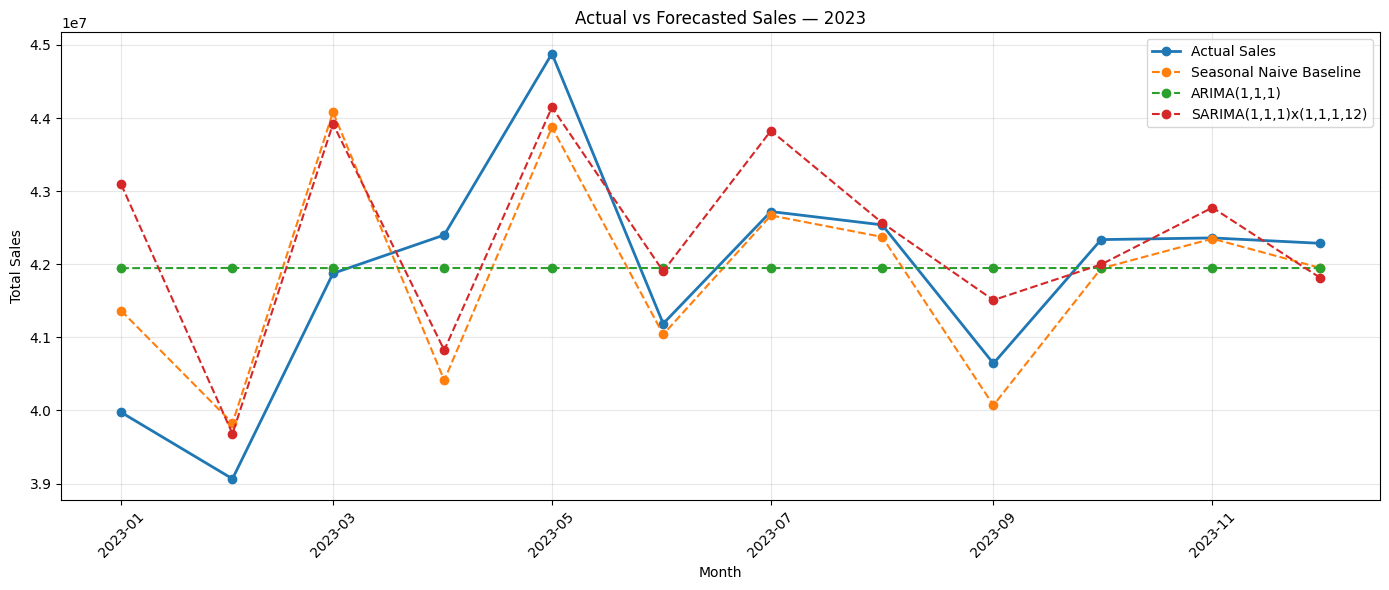

In [25]:
# Plotting actual 2023 sales against the forecasts from the baseline, ARIMA, and SARIMA models for visual comparison

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    test["Year-Month"],
    test["Total_Sales"],
    marker="o",
    linewidth=2,
    label="Actual Sales"
)

plt.plot(
    test["Year-Month"],
    test["Baseline_Forecast"],
    marker="o",
    linestyle="--",
    label="Seasonal Naive Baseline"
)

plt.plot(
    test["Year-Month"],
    test["ARIMA_Forecast"],
    marker="o",
    linestyle="--",
    label="ARIMA(1,1,1)"
)

plt.plot(
    test["Year-Month"],
    test["SARIMA_Forecast"],
    marker="o",
    linestyle="--",
    label="SARIMA(1,1,1)x(1,1,1,12)"
)

plt.title("Actual vs Forecasted Sales — 2023")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.legend()
plt.grid(True, alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [26]:
'''
It clearly shows the difference between the three forecasting approaches:

Actual Sales: fluctuates month-to-month.
Seasonal Naive: follows the previous year's corresponding month, so it tracks the seasonal pattern fairly well.
ARIMA: stays almost flat around ₹41.95M, so it does not capture the monthly seasonal fluctuations well.
SARIMA: captures some of the monthly variation and is visibly closer to actual sales in several months.
'''

"\nIt clearly shows the difference between the three forecasting approaches:\n\nActual Sales: fluctuates month-to-month.\nSeasonal Naive: follows the previous year's corresponding month, so it tracks the seasonal pattern fairly well.\nARIMA: stays almost flat around ₹41.95M, so it does not capture the monthly seasonal fluctuations well.\nSARIMA: captures some of the monthly variation and is visibly closer to actual sales in several months.\n"

In [27]:
# Preparing the complete 2019–2023 monthly sales series for generating future sales forecasts

full_series = (
    monthly_sales
    .set_index("Year-Month")["Total_Sales"]
    .asfreq("MS")
)

print("Full Series Length:", len(full_series))
print("Start:", full_series.index.min())
print("End:", full_series.index.max())
print("Missing Values:", full_series.isna().sum())

display(full_series.tail(12))

Full Series Length: 60
Start: 2019-01-01 00:00:00
End: 2023-12-01 00:00:00
Missing Values: 0


Year-Month
2023-01-01    39973456.60
2023-02-01    39064577.96
2023-03-01    41875082.29
2023-04-01    42400498.84
2023-05-01    44882357.95
2023-06-01    41187338.18
2023-07-01    42721138.18
2023-08-01    42538982.80
2023-09-01    40642795.64
2023-10-01    42337414.55
2023-11-01    42360455.29
2023-12-01    42286588.13
Freq: MS, Name: Total_Sales, dtype: float64

In [28]:
# Generating twelve future monthly sales forecasts for 2024 using the seasonal naive forecasting approach

future_dates = pd.date_range(
    start="2024-01-01",
    periods=12,
    freq="MS"
)

future_forecast = pd.DataFrame({
    "Year-Month": future_dates,
    "Forecasted_Sales": full_series.iloc[-12:].values
})

display(future_forecast)

,Year-Month,Forecasted_Sales
0,2024-01-01,39973456.60
1,2024-02-01,39064577.96
2,2024-03-01,41875082.29
3,2024-04-01,42400498.84
4,2024-05-01,44882357.95
5,2024-06-01,41187338.18
6,2024-07-01,42721138.18
7,2024-08-01,42538982.80
8,2024-09-01,40642795.64
9,2024-10-01,42337414.55


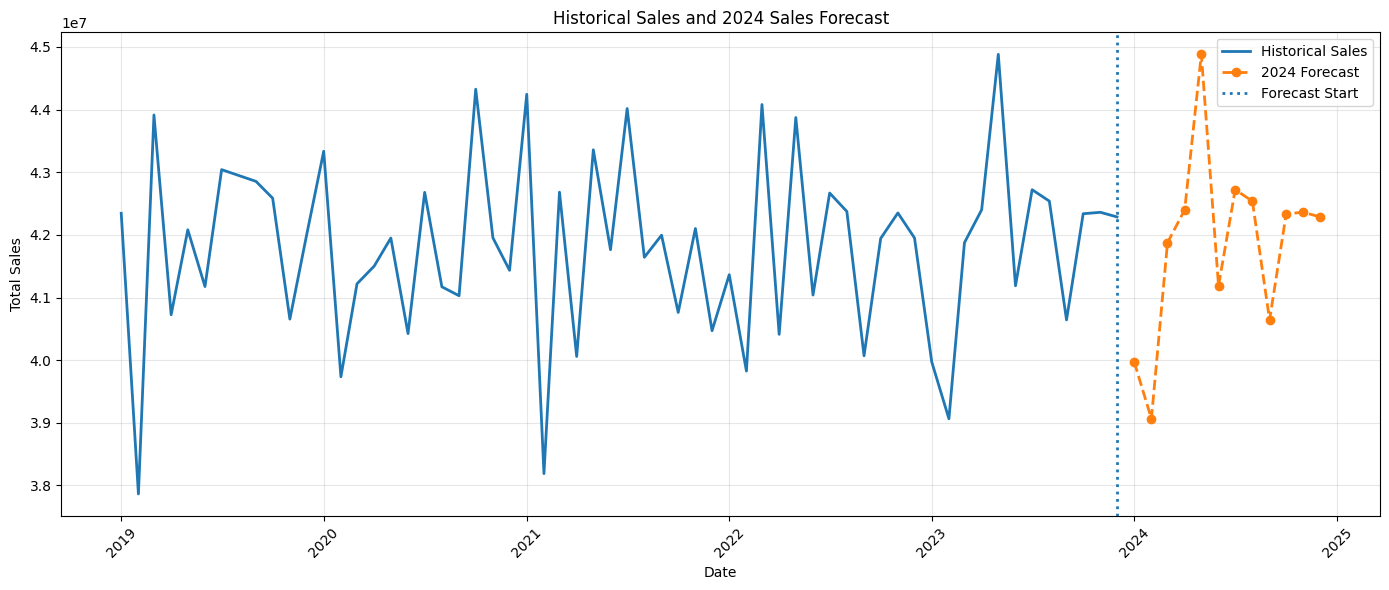

In [29]:
# Visualizing the historical monthly sales and the forecasted monthly sales for 2024

plt.figure(figsize=(14, 6))

plt.plot(
    full_series.index,
    full_series.values,
    label="Historical Sales",
    linewidth=2
)

plt.plot(
    future_forecast["Year-Month"],
    future_forecast["Forecasted_Sales"],
    label="2024 Forecast",
    marker="o",
    linestyle="--",
    linewidth=2
)

plt.axvline(
    full_series.index[-1],
    linestyle=":",
    linewidth=2,
    label="Forecast Start"
)

plt.title("Historical Sales and 2024 Sales Forecast")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.legend()
plt.grid(True, alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [30]:
# Summarizing the forecasting results, model performance, and 2024 forecast range for the project report

best_model = forecast_comparison.loc[
    forecast_comparison["MAPE"].idxmin(),
    "Model"
]

forecast_summary = {
    "Best Performing Model": best_model,
    "Best Model MAPE": forecast_comparison["MAPE"].min(),
    "2024 Forecast Total Sales": future_forecast["Forecasted_Sales"].sum(),
    "2024 Average Monthly Sales": future_forecast["Forecasted_Sales"].mean(),
    "Highest Forecast Month": future_forecast.loc[
        future_forecast["Forecasted_Sales"].idxmax(),
        "Year-Month"
    ].strftime("%B %Y"),
    "Highest Forecast Sales": future_forecast["Forecasted_Sales"].max(),
    "Lowest Forecast Month": future_forecast.loc[
        future_forecast["Forecasted_Sales"].idxmin(),
        "Year-Month"
    ].strftime("%B %Y"),
    "Lowest Forecast Sales": future_forecast["Forecasted_Sales"].min()
}

for key, value in forecast_summary.items():
    if isinstance(value, (int, float, np.number)):
        if "MAPE" in key:
            print(f"{key}: {value:.2f}%")
        else:
            print(f"{key}: ₹{value:,.2f}")
    else:
        print(f"{key}: {value}")

Best Performing Model: Seasonal Naive Baseline
Best Model MAPE: 1.81%
2024 Forecast Total Sales: ₹502,270,686.41
2024 Average Monthly Sales: ₹41,855,890.53
Highest Forecast Month: May 2024
Highest Forecast Sales: ₹44,882,357.95
Lowest Forecast Month: February 2024
Lowest Forecast Sales: ₹39,064,577.96


In [31]:
# Saving the future forecast and model comparison results into the processed data folder for use in the dashboard and final report

future_forecast.to_csv(
    "../data/processed/2024_sales_forecast.csv",
    index=False
)

forecast_comparison.to_csv(
    "../data/processed/forecast_model_comparison.csv",
    index=False
)

print("Forecasting outputs saved successfully.")
print("\nSaved Files:")
print("1. ../data/processed/2024_sales_forecast.csv")
print("2. ../data/processed/forecast_model_comparison.csv")

Forecasting outputs saved successfully.

Saved Files:
1. ../data/processed/2024_sales_forecast.csv
2. ../data/processed/forecast_model_comparison.csv
